In [19]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image
import matplotlib as mpl

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *


save_figure = False
dir_save_data = r'H:\commun\Utilisateur FNO\Nathan\Administratif\CSI\2e année\Figures'


In [20]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'16-Apr-2026_PaP_Pp10uW_ldap410nm_ldas_650'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

C:\Users\nberr\AppData\Local\Temp\ipykernel_18008\656513080.py:12: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_18008\656513080.py:12: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



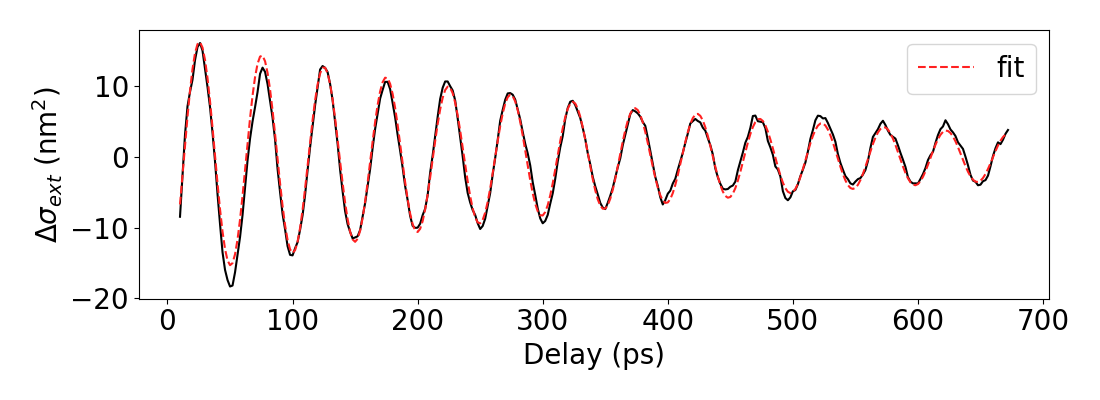

In [21]:
mpl.rcParams["font.size"] = 20
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -215347.14701364425 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma,  color = 'black')


ax.plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label='fit')



ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.legend(fontsize=20)
plt.tight_layout()

if save_figure :
    os.chdir(dir_save_data)
    plt.savefig('PaP acoustic signal on quartz.svg')
    plt.savefig('PaP acoustic signal on quartz.png')

C:\Users\nberr\AppData\Local\Temp\ipykernel_18008\386001726.py:11: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_18008\386001726.py:11: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



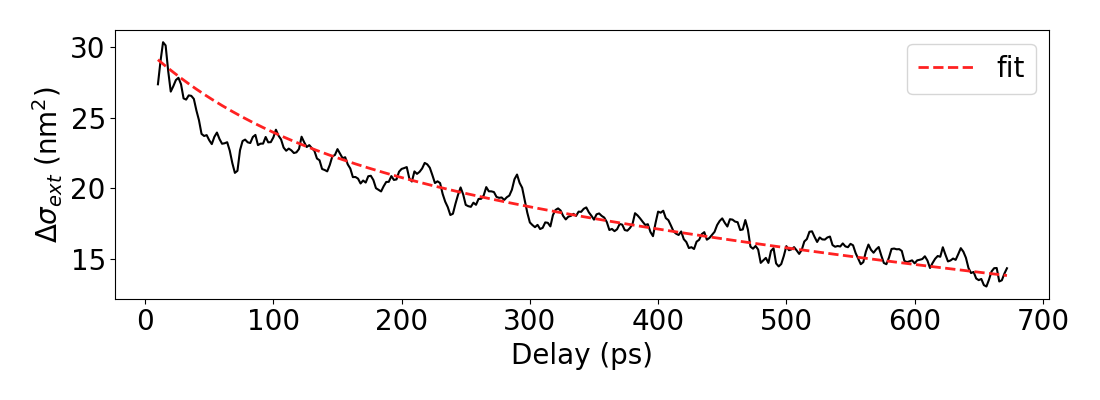

In [22]:
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -215347.14701364425 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay, (Trace.DTT - Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs']))*alpha_DTT_dsigma,  color = 'black')


ax.plot(Trace.delay,ExpDec2(Trace.delay,*Trace.thermal_fit['2 exp']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--', linewidth = 2, label='fit')



ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.legend(fontsize=20)
plt.tight_layout()

if save_figure :
    os.chdir(dir_save_data)
    plt.savefig('PaP thermal signal on quartz.svg')
    plt.savefig('PaP thermal signal on quartz.png')

C:\Users\nberr\AppData\Local\Temp\ipykernel_18008\2275308774.py:21: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_18008\2275308774.py:21: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



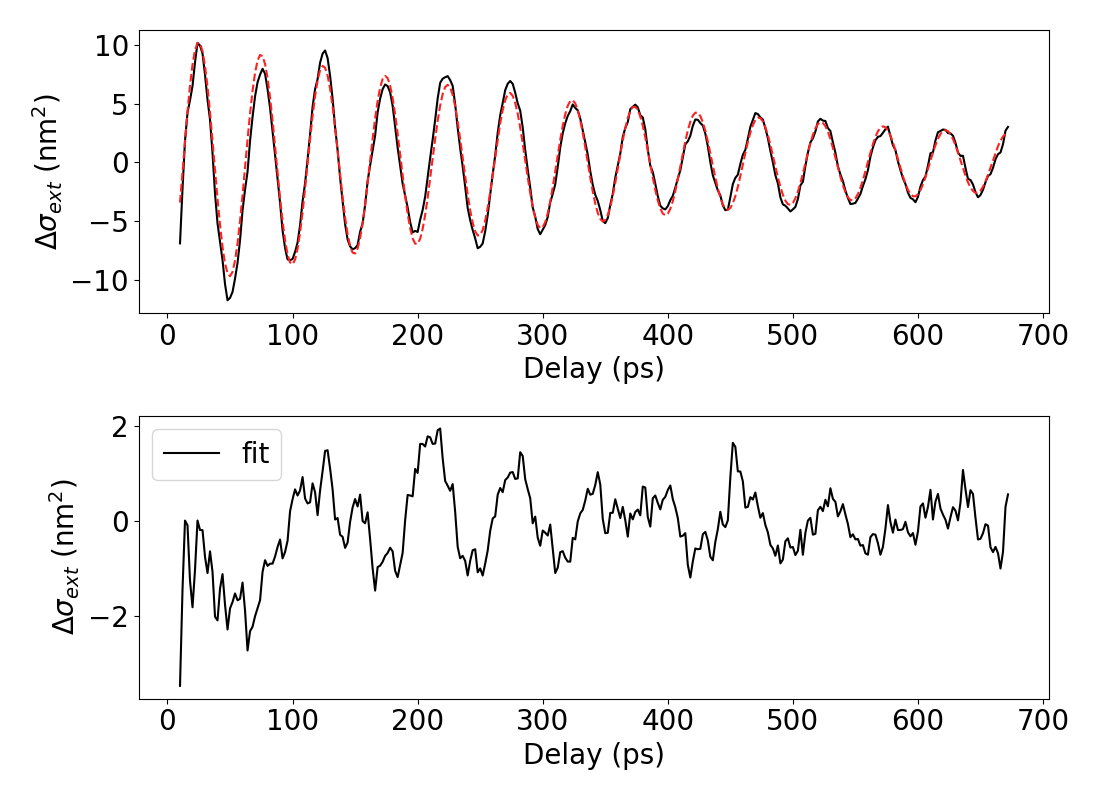

In [23]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D2 zone1\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'16-Apr-2026_PaP_Pp10uW_ldap410nm_ldas_640'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)
mpl.rcParams["font.size"] = 20
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -215347.14701364425 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,8), nrows=2)

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[0].plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma,  color = 'black')
ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label='fit')
ax[0].set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax[0].set_xlabel('Delay (ps)')


ax[1].plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma-Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, color= "black",label='fit')

ax[1].set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax[1].set_xlabel('Delay (ps)')


#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.legend(fontsize=20)
plt.tight_layout()

if save_figure :
    os.chdir(dir_save_data)
    plt.savefig('PaP acoustic signal on quartz.svg')
    plt.savefig('PaP acoustic signal on quartz.png')